# Homework 11 — Attention and Transformers (PyTorch)
**CSCI1409 Deep Learning | Aidyn Abirov | Week 11**

In this homework you build a transformer **from your own parts**: attention → one attention head → multi-head attention → transformer block → a full model, which you then train on two tasks.

Fill in every `# TODO`. Do **not** change the `assert` lines: they tell you when a cell is correct. Write your explanations in the **Your answer** cells.


- Save as `Surname_Firstname_Homework11.ipynb`, restart the kernel, **Run All**, and submit via Teams.
- **Google Colab recommended:** *Runtime → Change runtime type → T4 GPU*. The required parts also run on a laptop CPU in a couple of minutes; the optional Shakespeare part at the end needs the GPU.

In [3]:
import os, math, time, random, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_printoptions(precision=4, sci_mode=False)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
count = lambda m: sum(p.numel() for p in m.parameters())   # number of parameters of a model

device: cpu


## Task 1 — Attention by hand and from scratch ( about 35 minutes)

Each token asks a **query** $q$; every token offers a **key** $k$ and a **value** $v$. Attention compares the query with all keys, turns the scores into weights with softmax, and returns the weighted average of the values:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V$$

where $d_k$ is the length of a query/key vector.

**1a. By hand.** Three tokens with $d_k = 4$ (so $\sqrt{d_k} = 2$). In **self-attention** the queries and keys come from the same tokens; here $Q = K$:

| token | query = key | value |
|---|---|---|
| 1 | (1, 0, 1, 0) | (1, 0) |
| 2 | (0, 1, 0, 1) | (0, 1) |
| 3 | (1, 1, 1, 1) | (1, 1) |

For **token 1** only, compute: the three scores $q_1 \cdot k_j$, the scaled scores (divide by 2), the three attention weights (softmax; 4 decimals; a calculator is fine), and the output (the weighted sum of the values).

In [4]:
# TODO: your hand results for token 1
hand_weights_1 = torch.tensor([0.4223, 0.1554, 0.4223])
hand_output_1 = torch.tensor([0.8446, 0.5777])

**1b. From scratch.** Write `attention`. It must work for a single sequence `(T, d)` and for a batch `(batch, T, d)`, and return the output **and** the attention weights. Ignore `mask` for now (1c). Do not call `F.scaled_dot_product_attention` inside it.

Hints: `K.transpose(-2, -1)` swaps the last two dimensions; softmax goes over the **last** dimension.

In [5]:
def attention(Q, K, V, mask=None):
    # TODO 1: scores = Q K^T / sqrt(d_k)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(K.size(-1)) # matmul is used for matrix multiplication, transpose is used to get K^T, and size(-1) gives d_k
    # TODO 2 (for 1c): if mask is given, set the scores where mask is False to -inf (hint: scores.masked_fill(~mask, ...))
    if mask is not None:
        scores = scores.masked_fill(~mask, float('-inf'))
    # TODO 3: weights = softmax of the scores over the last dimension
    weights = F.softmax(scores, dim=-1) 
    # TODO 4: output = weights times V
    output = torch.matmul(weights, V)
    return output, weights

X = torch.tensor([[1., 0., 1., 0.], [0., 1., 0., 1.], [1., 1., 1., 1.]])
V = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
assert hand_weights_1.abs().sum() > 0, "fill in your hand results in 1a first"
out, w = attention(X, X, V)
print("weights:\n", w); print("output:\n", out)
assert torch.allclose(w[0], hand_weights_1, atol=1e-3) and torch.allclose(out[0], hand_output_1, atol=1e-3)
assert torch.allclose(w.sum(dim=-1), torch.ones(3)), "each row of weights must sum to 1"

Q, K, Vr = torch.randn(2, 5, 8), torch.randn(2, 5, 8), torch.randn(2, 5, 3)   # a batch of 2 sequences, 5 tokens
assert torch.allclose(attention(Q, K, Vr)[0], F.scaled_dot_product_attention(Q, K, Vr), atol=1e-5)
print("attention matches PyTorch")

weights:
 tensor([[0.4223, 0.1554, 0.4223],
        [0.1554, 0.4223, 0.4223],
        [0.2119, 0.2119, 0.5761]])
output:
 tensor([[0.8446, 0.5777],
        [0.5777, 0.8446],
        [0.7881, 0.7881]])
attention matches PyTorch


**1c. The causal mask.** When a model **generates** text, token $t$ must not look at future tokens $t+1, t+2, \dots$ (they do not exist yet). A causal mask allows each token to attend only to itself and to earlier tokens. Masked scores become $-\infty$, so their softmax weight is exactly 0. In this homework, **True means "allowed"**.

By hand:
1. Write the 4×4 causal mask as a list of lists.
2. With the causal mask, compute the outputs of **token 1** and **token 2** from the table in 1a. (Token 1 can see only itself; token 2 sees tokens 1 and 2.)

Then write `causal_mask` and make sure TODO 2 in your `attention` works.

In [6]:
# TODO: your hand answers
hand_mask_4 = [[True,  False, False, False],
               [True,  True,  False, False],
               [True,  True,  True,  False],
               [True,  True,  True,  True ]]
hand_causal_out = torch.tensor([[1.0, 0.0],      # token 1
                                [0.2689, 0.7311]])     # token 2

def causal_mask(T):
    # TODO: return a (T, T) boolean tensor that is True on and below the diagonal (hint: torch.tril, torch.ones)
    return torch.tril(torch.ones(T, T, dtype=torch.bool))

assert causal_mask(4).tolist() == hand_mask_4
out, w = attention(X, X, V, mask=causal_mask(3))
print("causal weights:\n", w)
assert torch.allclose(out[:2], hand_causal_out, atol=1e-3)
assert torch.allclose(attention(Q, K, Vr, causal_mask(5))[0], F.scaled_dot_product_attention(Q, K, Vr, is_causal=True), atol=1e-5)
print("causal attention matches PyTorch")

causal weights:
 tensor([[1.0000, 0.0000, 0.0000],
        [0.2689, 0.7311, 0.0000],
        [0.2119, 0.2119, 0.5761]])
causal attention matches PyTorch


**1d. Why divide by $\sqrt{d_k}$? An experiment.** For each $d \in \{4, 16, 64, 256, 1024\}$: draw one random query `torch.randn(1, d)` and 10 random keys `torch.randn(10, d)`, compute the scores, and record the **largest** softmax weight twice — without scaling and with scaling by $\sqrt{d}$. Then plot both lists against $d$ (log x-axis) in one figure.

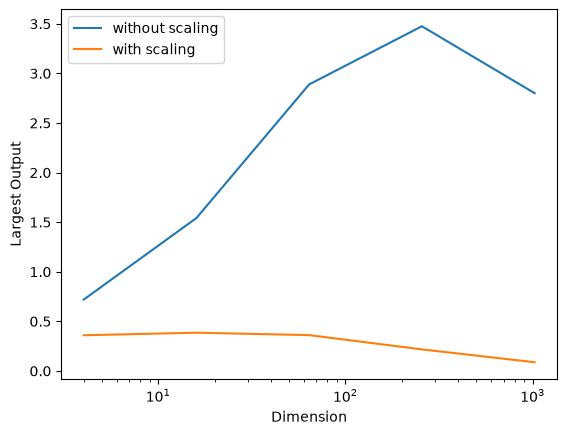

without scaling: [0.719 1.542 2.889 3.475 2.801]
with scaling:    [0.36  0.385 0.361 0.217 0.088]


In [7]:
torch.manual_seed(0)
dims = [4, 16, 64, 256, 1024]
largest_unscaled, largest_scaled = [], []
# TODO: the loop over dims (fill the two lists)
for dim in dims:
    Q, K, V = torch.randn(1, 1, dim), torch.randn(1, 1, dim), torch.randn(1, 1, dim)
    out_unscaled, _ = attention(Q, K, V)
    out_scaled, _ = attention(Q, K, V / math.sqrt(dim))
    largest_unscaled.append(out_unscaled.abs().max().item())
    largest_scaled.append(out_scaled.abs().max().item())
# TODO: the plot (two lines, log x-axis, axis labels, legend)
import matplotlib.pyplot as plt
plt.semilogx(dims, largest_unscaled, label="without scaling")
plt.semilogx(dims, largest_scaled, label="with scaling")
plt.xlabel("Dimension")
plt.ylabel("Largest Output")
plt.legend()
plt.show()

print("without scaling:", np.round(largest_unscaled, 3))
print("with scaling:   ", np.round(largest_scaled, 3))
assert len(largest_unscaled) == len(largest_scaled) == 5
assert largest_unscaled[-1] > 0.9 and largest_scaled[-1] < 0.7

**Questions 1.**
1. In 1a, why does token 1 give the same weight to tokens 1 and 3, and less to token 2? What does a large dot product $q \cdot k$ mean?
2. In 1c, why must a model that **generates** text use a causal mask? Would a model that **classifies** a whole sentence need one?
3. Describe your plot from 1d. Why is a weight close to 1 bad for learning? (Hint: what is the gradient of softmax when it is saturated?)

**Your answer:**

## Task 2 — Positions, one attention head, and the block ( about 40 minutes)

**2a. Attention does not know the order.** Shuffle the tokens of a sequence and run self-attention again. Complete the TODO and look at the result.

In [8]:
torch.manual_seed(0)
tokens = torch.randn(5, 8)                      # 5 tokens, 8 numbers each (no position information)
perm = torch.tensor([3, 0, 4, 1, 2])            # a shuffled order

out_original, _ = attention(tokens, tokens, tokens)
out_shuffled = out_original[perm]               # TODO: self-attention on tokens[perm]

print("output of shuffled input == shuffled output of original input:",
      torch.allclose(out_shuffled, out_original[perm], atol=1e-6))
assert torch.allclose(out_shuffled, out_original[perm], atol=1e-6)

output of shuffled input == shuffled output of original input: True


**2b. Sinusoidal positional encoding.** To give the model the order, we **add** a position vector to every token. The original Transformer uses sines and cosines of different frequencies:

$$PE(pos, 2i) = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE(pos, 2i+1) = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

By hand, with $d = 4$: write the encodings of position 0 and position 1 (4 numbers each, 4 decimals; angles in radians). Then write `sinusoidal_pe(max_len, d)`, which returns a `(max_len, d)` tensor. Try to do it without a Python loop.

Hints: `torch.arange(max_len)` gives 0, 1, 2, …; `torch.arange(0, d, 2)` gives $2i$ = 0, 2, 4, …; `pe[:, 0::2]` selects the even columns and `pe[:, 1::2]` the odd ones.

tensor([[0.0000, 1.0000, 0.0000, 1.0000],
        [0.8415, 0.5403, 0.0100, 0.9999]])


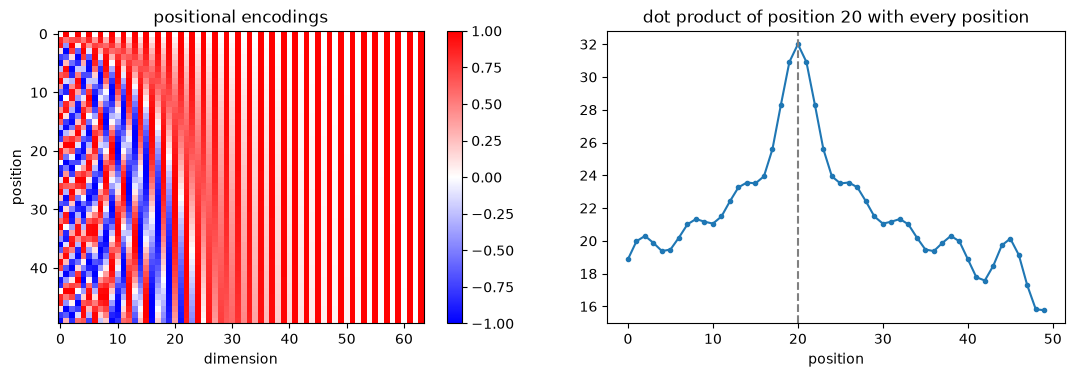

In [11]:
# TODO: your hand results
hand_pe = torch.tensor([[0.0, 1.0, 0.0, 1.0],     # position 0
                        [0.8415, 0.5403, 0.0100, 1.0]])    # position 1

def sinusoidal_pe(max_len, d):
    # TODO
    pe = torch.zeros(max_len, d)
    position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d, 2).float() *  (-math.log(10000.0) / d))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe

assert hand_pe.abs().sum() > 0, "fill in your hand results first"
print(sinusoidal_pe(2, 4))
assert torch.allclose(sinusoidal_pe(2, 4), hand_pe, atol=1e-3)
assert sinusoidal_pe(50, 64).shape == (50, 64)

pe = sinusoidal_pe(50, 64)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
im = axes[0].imshow(pe, cmap="bwr", vmin=-1, vmax=1, aspect="auto")
axes[0].set_xlabel("dimension"); axes[0].set_ylabel("position"); axes[0].set_title("positional encodings")
plt.colorbar(im, ax=axes[0])
axes[1].plot(pe @ pe[20], "o-", markersize=3)
axes[1].axvline(20, color="gray", ls="--"); axes[1].set_xlabel("position")
axes[1].set_title("dot product of position 20 with every position"); plt.show()

**2c. One attention head.** In a real transformer, $Q$, $K$, $V$ are not the raw tokens: each is computed from the tokens by its own learned linear layer. Write `SelfAttentionHead`:

- `__init__(d, head_size)`: three layers `self.query`, `self.key`, `self.value`, each `nn.Linear(d, head_size)` (use exactly these names);
- `forward(x, mask=None)`: `x` has shape `(batch, T, d)`; compute $Q, K, V$ with the three layers and return `attention(Q, K, V, mask)` — the output `(batch, T, head_size)` and the weights `(batch, T, T)`.

First compute by hand the number of parameters of one head with $d = 64$, `head_size` $= 16$.

In [18]:
# TODO: by hand
head_params_by_hand = 3 * (64 * 16 + 16)   # 3 layers, each has weights (64*16) + bias (16)

class SelfAttentionHead(nn.Module):
    # TODO: __init__ and forward
    def __init__(self, d, head_size):
        super().__init__()
        self.key = nn.Linear(d, head_size, bias=True)
        self.query = nn.Linear(d, head_size, bias=True)
        self.value = nn.Linear(d, head_size, bias=True)
        
    def forward(self, x, mask=None):
        k = self.key(x)
        q = self.query(x)
        v = self.value(x)
        return attention(q, k, v, mask=mask)
    
    

torch.manual_seed(0)
head = SelfAttentionHead(64, 16)
x = torch.randn(2, 5, 64)
out, w = head(x)
assert out.shape == (2, 5, 16) and w.shape == (2, 5, 5)
assert count(head) == head_params_by_hand

# A causal head must not look into the future: changing the LAST token may not change earlier outputs
x2 = x.clone(); x2[:, -1] = torch.randn(2, 64)
out_a, _ = head(x, causal_mask(5)); out_b, _ = head(x2, causal_mask(5))
assert torch.allclose(out_a[:, :4], out_b[:, :4]), "with the causal mask, positions 0-3 must not see position 4"
assert not torch.allclose(head(x)[0][:, :4], head(x2)[0][:, :4]), "without a mask they should see it"
print(f"SelfAttentionHead OK: {count(head)} parameters")

SelfAttentionHead OK: 3120 parameters


**2d. Count the parameters of a transformer block.** A block has two parts, each with a **residual connection** (the input is added back) and a **LayerNorm**:

```
x = x + MultiHeadAttention(LayerNorm(x))      # tokens exchange information
x = x + FeedForward(LayerNorm(x))             # each token is processed on its own: Linear(d, 2d) -> ReLU -> Linear(2d, d)
```

Multi-head attention with $d = 64$ and 4 heads = 4 of your heads with `head_size` = 16, whose outputs are concatenated (back to 64 numbers), followed by an output layer `Linear(64, 64)`. Compute **by hand**:

In [19]:
# TODO: fill in by hand
mha_params = 4 * head_params_by_hand + count(nn.Linear(64, 64))  # 4 heads + the output layer
ffn_params = count(nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64)))  # Linear(64, 128) -> ReLU -> Linear(128, 64)
layernorm_params = count(nn.LayerNorm(64))  # one nn.LayerNorm(64): a scale and a shift per dimension
block_params = mha_params + ffn_params + 2 * layernorm_params  # attention + feed-forward + 2 LayerNorms

assert mha_params == 4 * head_params_by_hand + count(nn.Linear(64, 64))
assert mha_params == count(nn.MultiheadAttention(64, 4)), "PyTorch's version has the same number"
assert ffn_params == count(nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64)))
assert layernorm_params == count(nn.LayerNorm(64))
assert block_params == mha_params + ffn_params + 2 * layernorm_params
print(f"one block: {block_params:,} parameters")

one block: 33,472 parameters


**Questions 2.**
1. What did 2a show? Why is this a problem for sentences like "dog bites man" and "man bites dog"? How does adding positional encodings fix it?
2. In the right plot of 2b, which positions have the largest dot product with position 20? What does that tell you about how the encodings describe "nearby" positions?
3. In 2c, why do we need learned layers for $Q$, $K$, $V$ instead of using the tokens directly as in 1a? Why is it useful to have several heads?
4. Does the number of parameters of a block depend on the sequence length? Compare with what you found for RNNs in the RNN/LSTM homework.

**Your answer:**

## Task 3 — Build and train your own transformer ( about 75 minutes)

**3a. Multi-head attention.** Write `MultiHeadAttention(d, n_heads)` from your `SelfAttentionHead`:
- `__init__`: `self.heads` = an `nn.ModuleList` of `n_heads` heads, each with `head_size = d // n_heads`; `self.out` = `nn.Linear(d, d)` (use exactly these names);
- `forward(x, mask=None)`: run every head, **concatenate** their outputs along the last dimension (back to `d` numbers per token), apply `self.out`. Return this output **and** the attention weights **averaged over the heads**, shape `(batch, T, T)`.

The check copies the weights of PyTorch's `nn.MultiheadAttention` into your module: if your code is right, both give the same result.

In [22]:
class MultiHeadAttention(nn.Module):
    # TODO: __init__ and forward
    def __init__(self, d, num_heads):
        super().__init__()
        self.heads = nn.ModuleList([SelfAttentionHead(d, d // num_heads) for _ in range(num_heads)])
        self.out = nn.Linear(d, d)

    def forward(self, x, mask=None):
        outs, weights = [], []
        for head in self.heads:
            o, w = head(x, mask=mask)      # o: (B, T, 16), w: (B, T, T)
            outs.append(o)
            weights.append(w)
        out = torch.cat(outs, dim=-1)                   # (B, T, 64)
        avg_w = torch.stack(weights, dim=0).mean(dim=0) # (B, T, T)
        return self.out(out), avg_w


def copy_weights_from(torch_mha, my_mha):
    """Copy nn.MultiheadAttention's weights into your module (given; do not change)."""
    d, hs = torch_mha.embed_dim, torch_mha.embed_dim // torch_mha.num_heads
    W, b = torch_mha.in_proj_weight, torch_mha.in_proj_bias          # Q, K, V weights stacked: (3d, d)
    with torch.no_grad():
        for h, head in enumerate(my_mha.heads):
            rows = slice(h * hs, (h + 1) * hs)
            for k, layer in enumerate([head.query, head.key, head.value]):
                layer.weight.copy_(W[k * d:(k + 1) * d][rows]); layer.bias.copy_(b[k * d:(k + 1) * d][rows])
        my_mha.out.weight.copy_(torch_mha.out_proj.weight); my_mha.out.bias.copy_(torch_mha.out_proj.bias)

torch.manual_seed(0)
mine, theirs = MultiHeadAttention(64, 4), nn.MultiheadAttention(64, 4, batch_first=True)
assert count(mine) == mha_params, "should match your count from 2d"
copy_weights_from(theirs, mine)
x = torch.randn(3, 7, 64)
for mask in [None, causal_mask(7)]:
    my_out, my_w = mine(x, mask)
    torch_mask = None if mask is None else ~mask           # PyTorch's nn.MultiheadAttention uses True = NOT allowed
    t_out, t_w = theirs(x, x, x, attn_mask=torch_mask)
    assert my_out.shape == (3, 7, 64) and my_w.shape == (3, 7, 7)
    assert torch.allclose(my_out, t_out, atol=1e-5) and torch.allclose(my_w, t_w, atol=1e-5)
print("MultiHeadAttention matches nn.MultiheadAttention")

MultiHeadAttention matches nn.MultiheadAttention


**3b. The transformer.** Write the two classes below. Use exactly the attribute names given, because later cells use them.

**`Block(d, n_heads)`**
- layers: `self.ln1 = nn.LayerNorm(d)`, `self.attn` = your `MultiHeadAttention(d, n_heads)`, `self.ln2 = nn.LayerNorm(d)`, `self.ffn` = `Linear(d, 2d) → ReLU → Linear(2d, d)`;
- `forward(x, mask=None)`: the two residual lines from 2d. Store the attention weights in `self.attn_weights` (use `.detach()`) so that we can plot them later.

**`TinyTransformer(vocab_size, d=64, n_heads=4, n_layers=2, max_len=32, causal=False, use_pos=True)`**
- store `self.max_len`, `self.causal`, `self.use_pos`;
- layers: `self.embed = nn.Embedding(vocab_size, d)` (token number → learned vector), the positional encoding `self.register_buffer("pe", sinusoidal_pe(max_len, d))` (fixed, not learned), `self.blocks` = an `nn.ModuleList` of `n_layers` blocks, a final `self.ln = nn.LayerNorm(d)`, and `self.head = nn.Linear(d, vocab_size)`;
- `forward(ids)`: `ids` has shape `(batch, T)`. Make the causal mask if `self.causal` (move it to `ids.device`), embed the ids, add `self.pe[:T]` if `self.use_pos`, pass through every block, then `self.head(self.ln(x))`. Output: `(batch, T, vocab_size)`.

In [23]:
class Block(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attn = MultiHeadAttention(d, n_heads)
        self.ln2 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(
            nn.Linear(d, 2 * d),
            nn.ReLU(),
            nn.Linear(2 * d, d),
        )

    def forward(self, x, mask=None):
        a, w = self.attn(self.ln1(x), mask)
        self.attn_weights = w.detach()
        x = x + a                        # residual 1: attention
        x = x + self.ffn(self.ln2(x))    # residual 2: feed-forward
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, d=64, n_heads=4, n_layers=2, max_len=32, causal=False, use_pos=True):
        super().__init__()
        self.max_len = max_len
        self.causal = causal
        self.use_pos = use_pos
        self.embed = nn.Embedding(vocab_size, d)
        self.register_buffer("pe", sinusoidal_pe(max_len, d))
        self.blocks = nn.ModuleList([Block(d, n_heads) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab_size)

    def forward(self, ids):
        T = ids.shape[1]
        mask = causal_mask(T).to(ids.device) if self.causal else None
        x = self.embed(ids)              # (B, T) -> (B, T, d)
        if self.use_pos:
            x = x + self.pe[:T]          # (T, d) is added to every item in the batch
        for block in self.blocks:
            x = block(x, mask)
        return self.head(self.ln(x))     # (B, T, vocab_size)

**3c. Learn to reverse a sequence.** Input: 8 random digits, e.g. `3 1 4 1 5 9 2 6`. Target: the same digits reversed, `6 2 9 5 1 4 1 3`. To produce output position $i$, the model must look up input position $7 - i$ — a job made for attention.

Write `train_reverse(use_pos, steps=1000)`:
1. set `torch.manual_seed(0)`; create a `TinyTransformer(vocab_size=10, max_len=L, use_pos=use_pos)` on `device` and an `Adam` optimizer with `lr=1e-3` (a variant of gradient descent; use it as a black box);
2. for each step: get a batch of 128 with `reverse_batch(128, gen)`, move it to `device`, compute the cross-entropy over all 128 × 8 positions (the reshape trick from the RNN/LSTM homework), and do the usual `zero_grad` / `backward` / `step`;
3. after training: switch to `model.eval()`, predict `x_test` (the most likely digit at each position) and compute the **digit accuracy** (share of correct digits) and the **whole-sequence accuracy** (share of sequences with all 8 digits correct; hint: `.all(dim=1)`);
4. print both and return `model, digit_acc, seq_acc`.

Train once with and once without positional encoding. The plot is given.

In [24]:
def train_reverse(use_pos, steps=1000):
    torch.manual_seed(0)
    model = TinyTransformer(vocab_size=10, max_len=L, use_pos=use_pos).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    model.train()
    for step in range(steps):
        x, y = reverse_batch(128, gen)
        x, y = x.to(device), y.to(device)
        logits = model(x)                                   # (128, 8, 10)
        loss = nn.functional.cross_entropy(
            logits.reshape(-1, 10),                         # (1024, 10)
            y.reshape(-1),                                  # (1024,)
        )
        opt.zero_grad()
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        pred = model(x_test).argmax(dim=-1)                 # (2000, 8)
    correct = (pred == y_test)                              # (2000, 8) True/False
    digit_acc = correct.float().mean().item()
    seq_acc = correct.all(dim=1).float().mean().item()

    print(f"use_pos={use_pos}: loss {loss.item():.3f}, "
          f"digit acc {digit_acc:.3f}, sequence acc {seq_acc:.3f}")
    return model, digit_acc, seq_acc

**3d. A tiny GPT for names.** Same data as the RNN/LSTM homework (the data code is given). Now **you** write:

1. **The training loop.** A causal `TinyTransformer(vocab_size=V, max_len=T, causal=True)` on `device`, `Adam` with `lr=3e-3`, 5 epochs over `x_train` in shuffled mini-batches of 64 (as in the RNN/LSTM homework). After every epoch, compute the validation loss on `x_val`, `y_val` (with `torch.no_grad()` and `gpt.eval()`), append it to `history`, and print it. Compare with the RNN/LSTM homework (reference: RNN ≈ 2.18, LSTM ≈ 2.10).
2. **`generate(model, n_names, seed)`.** For each name: start from `ids = [0]` (the `.` symbol); repeat up to 30 times: take the **last `model.max_len` ids** as a `(1, length)` tensor on `device`, run the model, take the softmax of the scores at the **last** position, sample one id with `torch.multinomial(probs, 1, generator=gen)` (keep `probs` on the CPU), stop if it is `0`, otherwise append it. Return the list of names as strings. Unlike an RNN, a transformer has **no hidden state**: it re-reads the whole name at every step.

In [25]:
if not os.path.exists("names.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/makemore/master/names.txt", "names.txt")
words = open("names.txt").read().split()
random.Random(0).shuffle(words)
chars = "." + "abcdefghijklmnopqrstuvwxyz"
V = len(chars); stoi = {ch: i for i, ch in enumerate(chars)}
T = 20

def make_chunks(names):
    text = "." + ".".join(names) + "."
    ids = torch.tensor([stoi[ch] for ch in text])
    n = (len(ids) - 1) // T
    return ids[:n * T].view(n, T), ids[1:n * T + 1].view(n, T)

split = int(0.9 * len(words))
x_train, y_train = make_chunks(words[:split])
x_val, y_val = (t.to(device) for t in make_chunks(words[split:]))
print("train:", tuple(x_train.shape), " val:", tuple(x_val.shape))

train: (10272, 20)  val: (1135, 20)


In [27]:
torch.manual_seed(0)
history = []
t0 = time.time()
gpt = TinyTransformer(vocab_size=V, max_len=T, causal=True).to(device)
opt = torch.optim.Adam(gpt.parameters(), lr=3e-3)

for epoch in range(5):
    gpt.train()
    perm = torch.randperm(len(x_train))                     # new random order every epoch
    for i in range(0, len(x_train), 64):
        idx = perm[i:i + 64]
        xb, yb = x_train[idx].to(device), y_train[idx].to(device)
        logits = gpt(xb)                                    # (64, T, V)
        loss = nn.functional.cross_entropy(logits.reshape(-1, V), yb.reshape(-1))
        opt.zero_grad()
        loss.backward()
        opt.step()

    gpt.eval()
    with torch.no_grad():
        val_logits = gpt(x_val.to(device))
        val_loss = nn.functional.cross_entropy(
            val_logits.reshape(-1, V), y_val.to(device).reshape(-1)
        ).item()
    history.append(val_loss)
    print(f"epoch {epoch + 1}: val loss {val_loss:.3f}")
print(f"{count(gpt):,} parameters, {time.time() - t0:.0f} seconds on {device}")
assert len(history) == 5 and history[-1] < 2.25, "the tiny GPT should reach a validation loss below 2.25"


def generate(model, n_names, seed=0):
    gen = torch.Generator().manual_seed(seed)
    model.eval()
    names = []
    with torch.no_grad():
        for _ in range(n_names):
            ids = [0]                                       # start with "."
            for _ in range(30):
                context = torch.tensor([ids[-model.max_len:]], device=device)  # (1, length)
                logits = model(context)                     # (1, length, V)
                probs = torch.softmax(logits[0, -1], dim=-1).cpu()  # scores at the last position
                nxt = torch.multinomial(probs, 1, generator=gen).item()
                if nxt == 0:                                # "." means the name ended
                    break
                ids.append(nxt)
            names.append("".join(chars[i] for i in ids[1:]))  # skip the starting "."
    return names

samples = generate(gpt, 200, seed=1)
print("generated:", ", ".join(samples[:15]))
print(f"{sum(s in set(words) for s in samples) / 200:.0%} of 200 generated names appear in the training list")
assert len(samples) == 200 and all(set(s) <= set(chars[1:]) for s in samples)

epoch 1: val loss 2.262
epoch 2: val loss 2.214
epoch 3: val loss 2.172
epoch 4: val loss 2.159
epoch 5: val loss 2.136
70,555 parameters, 9 seconds on cpu
generated: arion, gilmara, delyxah, sun, dezabem, rari, rizleigh, kyum, zaphony, aera, dacelianoni, linysh, zachaira, typron, zafi
18% of 200 generated names appear in the training list


**3e. Look inside the GPT.** Run the cell: it shows, for each block, where every letter of a name looks when predicting the next letter.

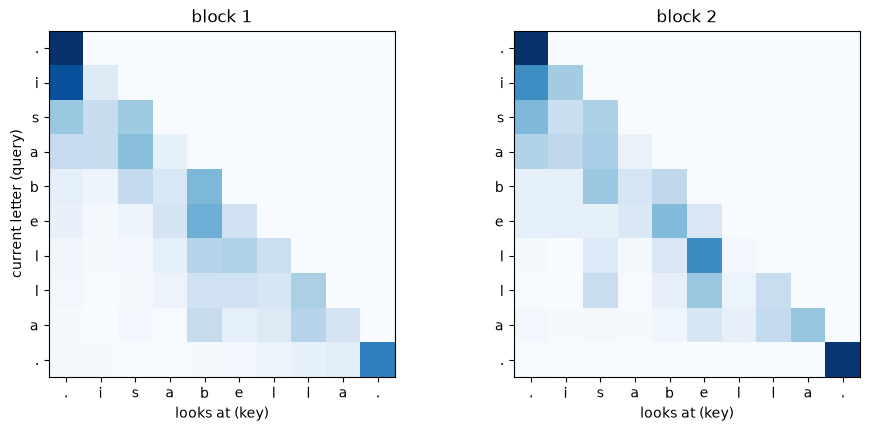

In [28]:
name = ".isabella."
ids = torch.tensor([[stoi[ch] for ch in name]], device=device)
with torch.no_grad():
    gpt(ids)
fig, axes = plt.subplots(1, len(gpt.blocks), figsize=(11, 4.5))
for k, (ax, block) in enumerate(zip(axes, gpt.blocks)):
    ax.imshow(block.attn_weights[0].cpu(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(name))); ax.set_xticklabels(list(name))
    ax.set_yticks(range(len(name))); ax.set_yticklabels(list(name))
    ax.set_xlabel("looks at (key)"); ax.set_title(f"block {k + 1}")
axes[0].set_ylabel("current letter (query)"); plt.show()

**Questions 3.**
1. In 3c, compare the accuracy with and without positional encoding. Why does the model without positions fail? Connect your answer to 2a.
2. Describe the attention map in 3c. Why does it have that shape?
3. In 3e, why is everything above the diagonal empty (white)? Find one letter that looks mostly at itself or the previous letter and one that looks further back.
4. Compare your tiny GPT with the RNN and LSTM from the RNN/LSTM homework (validation loss and names). Names are short — where would you expect a transformer to have a bigger advantage?
5. An RNN carries a hidden state from step to step; your `generate` does not. How does the transformer "remember" the beginning of the name, and what is the cost of doing it this way?

**Your answer:**

**Optional — Shakespeare on a GPU (not required).** In Google Colab, switch to a T4 GPU, set `RUN_SHAKESPEARE = True`, and run the cell. It trains a bigger version of **your** TinyTransformer (4 blocks, $d = 128$, context of 128 characters) on 1 MB of Shakespeare's plays, then writes new "Shakespeare". Report the training time and paste a few lines it wrote. On a laptop CPU this takes too long — that is why GPUs matter for transformers.

In [29]:
RUN_SHAKESPEARE = False
if RUN_SHAKESPEARE:
    if not os.path.exists("shakespeare.txt"):
        urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "shakespeare.txt")
    text = open("shakespeare.txt").read()
    vocab = sorted(set(text)); s2i = {c: i for i, c in enumerate(vocab)}
    data = torch.tensor([s2i[c] for c in text], device=device)
    ctx = 128
    torch.manual_seed(0)
    bard = TinyTransformer(vocab_size=len(vocab), d=128, n_heads=4, n_layers=4, max_len=ctx, causal=True).to(device)
    opt = torch.optim.Adam(bard.parameters(), lr=1e-3)
    t0 = time.time()
    for step in range(3000):
        starts = torch.randint(0, len(data) - ctx - 1, (64,), device=device)
        xb = torch.stack([data[s:s + ctx] for s in starts]); yb = torch.stack([data[s + 1:s + ctx + 1] for s in starts])
        loss = F.cross_entropy(bard(xb).reshape(-1, len(vocab)), yb.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 500 == 0:
            print(f"step {step}: loss {loss.item():.3f} ({time.time() - t0:.0f} s)")
    print(f"training took {time.time() - t0:.0f} seconds on {device}")
    bard.eval(); ids = [s2i["\n"]]
    with torch.no_grad():
        for _ in range(500):
            probs = F.softmax(bard(torch.tensor([ids[-ctx:]], device=device))[0, -1], dim=0)
            ids.append(torch.multinomial(probs, 1).item())
    print("".join(vocab[i] for i in ids))

## Submission checklist
- [ ] Every `# TODO` filled, every `assert` passes, **Kernel → Restart & Run All** works
- [ ] All **Your answer** cells written (Questions 1, 2, 3)
- [ ] Hand calculations for 1a, 1c, 2b, 2c, and 2d done on paper first
- [ ] Tasks 1–2 done without AI; references listed
- [ ] Task 3 AI use recorded (tool + what for), or "no AI used"

**References / AI use:**